# Defensive Alignment Causal RL — Pipeline Walkthrough

Every defense in the league, every snap — runs included. Before the ball is snapped a
coordinator commits to an **alignment**: which personnel package is on the field (base,
nickel, dime) and how many defenders stand in the box. Both are chosen pre-snap and both
are charted on essentially every play, so this is an action a coordinator can actually
call and we can actually observe.

The pipeline recommends an alignment for each situation, then a coverage and pressure call
to go with it, and evaluates both from logged games alone. The central difficulty is that the offense *responds* to the
alignment — load the box and it throws; show dime and it runs — so the value of a call is
a mixture over the offense's response, not the outcome of one branch. And coordinators
choose alignments for reasons the data never recorded, which affect outcomes too.

Every estimate below is stamped with the causal graph it assumed, and every headline claim
is checked against a simulated league whose true answer is known.

## Setup

In [1]:
import os, sys, warnings, logging
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore"); logging.disable(logging.WARNING)

here = os.getcwd()
root = here if os.path.exists(os.path.join(here, "configs")) else os.path.dirname(here)
os.chdir(root); sys.path.insert(0, root)

from src.data.load import (load_pbp, load_ftn, merge_ftn, ftn_coverage,
                           generate_synthetic_alignment, true_alignment_value)
from src.data.features import (assert_ftn_coverage, build_dataset, time_aware_split,
                               PACKAGES, FRONTS)
from src.scm import graph as scm
from src.scm import identify
from src.models.behavior.propensity import fit_behavior_model
from src.models.behavior.judge import fit_judge_behavior
from src.models.calibration import weight_balance
from src.models.outcome.q_model import fit_q_model, crossfit_q, fit_q_ensemble
from src.ope.direct_method import behavior_recovery_check
from src.ope.doubly_robust import dr_policy_value
from src.ope.ladder import ope_ladder
from src.ope.sensitivity import sensitivity_bounds, attach as attach_sensitivity
from src.policy.safe import learn_safe_policy
from src.evaluation import compare_to_baseline

# Chart tokens: validated categorical slots (blue, orange, aqua), ink for text,
# a recessive grid. Aqua sits below 3:1 contrast, so it only marks directly-labeled items.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda v: f"{v:+.4f}")

cfg = yaml.safe_load(open("configs/v3.yaml"))
graph = scm.graph_for(cfg); gv = graph.version_tag()
clip = cfg["ope"]["weight_clip"]
print("graph:", gv)

graph: v3.2+8e2de51a8e2b


## Step 1 — Data: every defense, every snap

Play-by-play from nflfastR, pre-snap charting from FTN. Personnel comes from nflfastR's
participation data; the box count from FTN. A snap enters the sample if both are charted —
which is ~99.5% of scrimmage snaps, runs and passes alike.

In [2]:
S = cfg["data"]["seasons"]
pbp = merge_ftn(load_pbp(S, cfg["data"]["cache_dir"]), load_ftn(S, cfg["data"]["cache_dir"]))
assert_ftn_coverage(pbp, cfg)
ds = build_dataset(pbp, cfg)
d = ds.df
print(f"{len(d):,} snaps · {d['defteam'].nunique()} defenses · seasons {S} · "
      f"{(d['play_type'] == 'run').mean():.1%} runs")
align = (d.groupby("action_label")
          .agg(snaps=("reward", "size"), run_rate=("play_type", lambda x: (x == "run").mean()))
          .reindex(ds.action_labels.values()))
align["share"] = align["snaps"] / align["snaps"].sum()
align[["snaps", "share", "run_rate"]].style.format({"snaps": "{:,}", "share": "{:.1%}", "run_rate": "{:.0%}"})

139,670 snaps · 32 defenses · seasons [2022, 2023, 2024, 2025] · 42.6% runs


,snaps,share,run_rate
action_label,,,
base_box_le5,"2,005",1.4%,30%
base_box6,"9,855",7.1%,54%
base_box7,"16,934",12.1%,65%
base_box_ge8,"7,369",5.3%,75%
nickel_box_le5,"14,972",10.7%,17%
nickel_box6,"54,102",38.7%,39%
nickel_box7,"16,661",11.9%,53%
nickel_box_ge8,"3,079",2.2%,71%
dime_plus_box_le5,"7,966",5.7%,12%


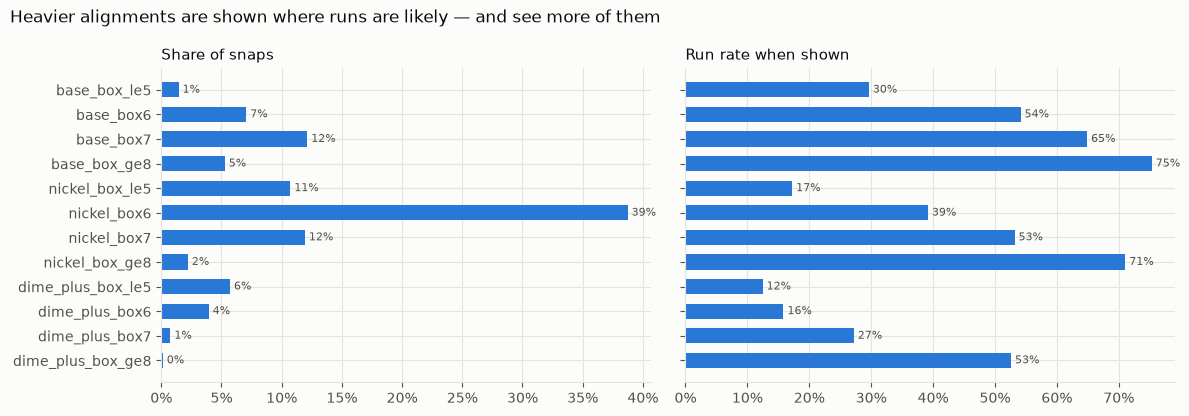

In [3]:
# Two measures on different scales -> two panels, never one chart with two axes.
order = list(ds.action_labels.values())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, col, title, fmt in [(axes[0], "share", "Share of snaps", "{:.0%}"),
                            (axes[1], "run_rate", "Run rate when shown", "{:.0%}")]:
    ax.barh(order, align.loc[order, col], color=BLUE, height=0.62)
    for y, v in enumerate(align.loc[order, col]):
        ax.text(v, y, " " + fmt.format(v), va="center", fontsize=8, color=INK2)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].invert_yaxis()
fig.suptitle("Heavier alignments are shown where runs are likely — and see more of them",
             x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.show()

The run rate climbs from ~13% against dime with a light box to ~75% against base with eight
or more in the box. That gradient is *two things at once*: coordinators show heavy looks when
they expect a run (selection), and offenses check away from a loaded box (deterrence).
Untangling them is the whole job — which is why a raw comparison of these rates would say
nothing about what an alignment *does*.

In [4]:
train, test = time_aware_split(ds, cfg["data"]["holdout_season"])
print(f"train {len(train.df):,} snaps (< {cfg['data']['holdout_season']}) · "
      f"holdout {len(test.df):,} (>= {cfg['data']['holdout_season']})")

train 105,221 snaps (< 2025) · holdout 34,449 (>= 2025)


## Step 2 — The causal graph

The treatment is the alignment. Two variables sit *downstream* of it and so must not be
adjusted for: the offense's run/pass choice (it responds to the look) and the coverage
the coordinator pairs with the alignment. A third is **execution** — everything decided after
the snap: pass rush, coverage technique, blocking, tackling, the quarterback's accuracy. It is
what turns a call and a set of players into a result, so it sits between them and EPA, and it
is unobserved here. The estimand is the alignment's **total** effect, travelling through all
three.

Team identity is a confounder — a defense's roster and scheme drive its calls and its outcomes
— and so is current quality, proxied by recency-weighted historical EPA for the quarterback,
the defense, and the offense as a unit (a half-life of ~250 plays, chosen because it best
predicted each offense's next game). The coordinator's hidden read is the unobserved confounder
the sensitivity analysis bounds.

The read is a read *of* something: the offense's **plan** — what it means to run before it
breaks the huddle. The plan is never recorded (the run/pass call in the data is what the
offense did, after any check at the line), but it shapes the personnel and formation the
offense shows, the call it runs, and what the coordinator expects. That opens a path the
adjustment set cannot close: alignment ← read ← plan → run/pass → EPA. A coordinator who reads
a run loads the box, and runs are cheap for a defense, so a heavy box is credited with
outcomes the read earned. The data shows the footprint: heavy boxes face *more* runs than
the pre-snap state predicts, where deterrence alone would predict fewer. The plan adds nothing
to adjust for — it only names the bias — and it makes splitting an alignment's effect by run
versus pass a mistake: the run/pass call is now a descendant of the confounder.

SCM — personnel package x front, every snap [v3.2+8e2de51a8e2b]
  treatment=def_alignment, outcome=epa
  adjustment set (condition on): ['game_state', 'off_formation', 'off_personnel', 'off_tendencies', 'player_proxies', 'team_identity']
    -> 28 feature columns
  mediators (do NOT condition on): ['def_coverage', 'execution', 'off_playcall']
  unobserved confounders: ['coach_read', 'execution', 'offense_intent'] (bounded by the sensitivity analysis)
    no dropback selection: every FTN- and personnel-charted scrimmage snap, runs included


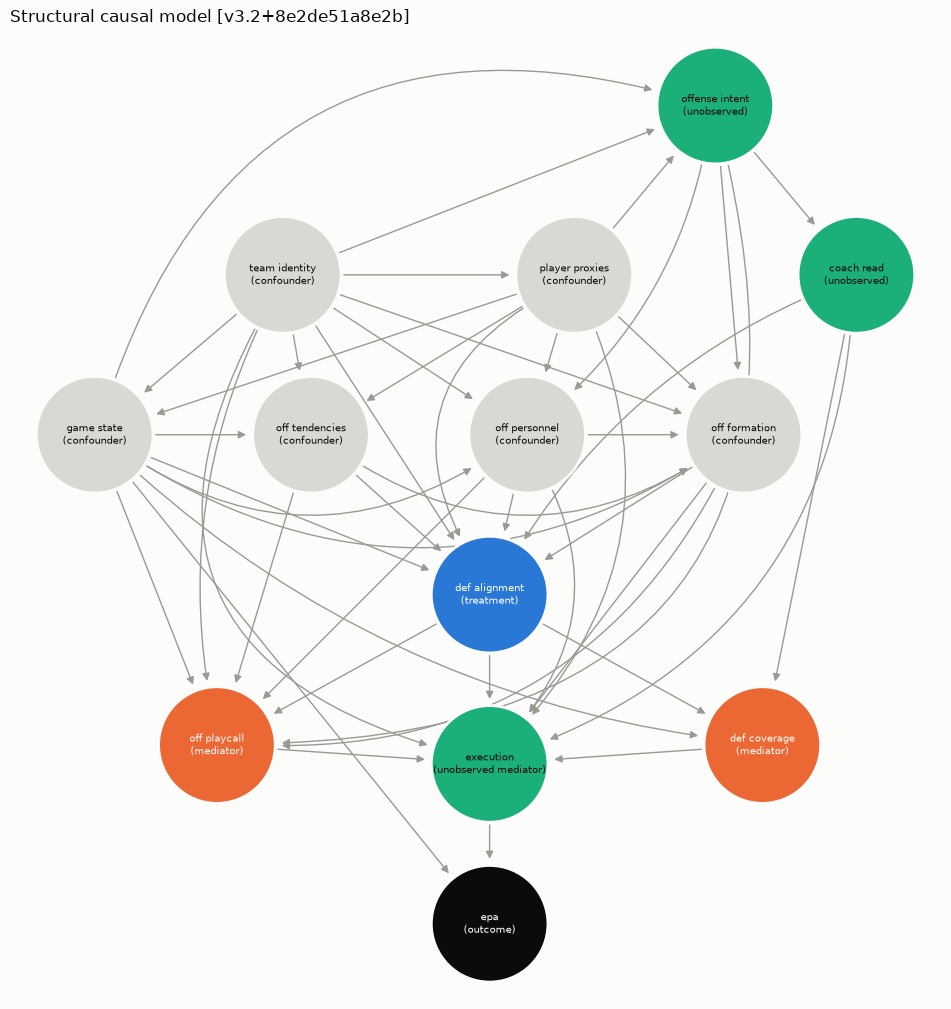

In [5]:
print(graph.describe())
from matplotlib.patches import Circle, FancyArrowPatch
# Layered: identity and quality, the offense's pre-snap presentation, the call,
# what happens after the snap, the result.
pos = {"offense_intent": (2.4, 5.5),
       "team_identity": (-2.2, 3.7), "player_proxies": (0.9, 3.7), "coach_read": (3.9, 3.7),
       "game_state": (-4.2, 2.0), "off_tendencies": (-1.9, 2.0), "off_personnel": (0.4, 2.0),
       "off_formation": (2.7, 2.0), "def_alignment": (0.0, 0.3),
       "off_playcall": (-2.9, -1.3), "execution": (0.0, -1.5), "def_coverage": (2.9, -1.3),
       "epa": (0.0, -3.2)}
R = 0.62  # node radius, data units (equal aspect keeps data and screen geometry aligned)

def _curve(p0, p2, rad, n=60):
    p0, p2 = np.asarray(p0, float), np.asarray(p2, float)
    c = (p0 + p2) / 2 + rad * np.array([p2[1] - p0[1], -(p2[0] - p0[0])])
    t = np.linspace(0.05, 0.95, n)[:, None]
    return (1 - t) ** 2 * p0 + 2 * (1 - t) * t * c + t ** 2 * p2, c

def _route(s, t):
    """Smallest curvature that keeps an edge clear of every node it doesn't touch —
    an edge through an untouched node reads as a causal claim that isn't there."""
    others = [np.asarray(p) for n, p in pos.items() if n not in (s, t)]
    def clear(r): return min(np.linalg.norm(_curve(pos[s], pos[t], r)[0] - o, axis=1).min() for o in others)
    for r in (0, .15, -.15, .3, -.3, .45, -.45, .6, -.6):
        if clear(r) > R * 1.08: return r
    return max((0, .3, -.3, .6, -.6), key=clear)

role = {graph.treatment: (BLUE, "white", "treatment"), graph.outcome: (INK, "white", "outcome")}
role |= {m: (ORANGE, "white", "mediator") for m in graph.mediators}
role |= {u: (AQUA, INK, "unobserved") for u in graph.unobserved}
role[scm.EXECUTION] = (AQUA, INK, "unobserved mediator")
fig, ax = plt.subplots(figsize=(11, 10.2)); ax.grid(False); ax.axis("off")
ax.set_xlim(-5.1, 4.8); ax.set_ylim(-4.0, 6.3); ax.set_aspect("equal")
for s, t in graph.edges:
    rad = _route(s, t); _, c = _curve(pos[s], pos[t], rad)
    p0, p2 = np.asarray(pos[s], float), np.asarray(pos[t], float)
    a = p0 + R * (c - p0) / np.linalg.norm(c - p0); b = p2 + (R + 0.04) * (c - p2) / np.linalg.norm(c - p2)
    ax.add_patch(FancyArrowPatch(a, b, connectionstyle=f"arc3,rad={rad}", arrowstyle="-|>",
                                 mutation_scale=11, lw=1.0, color="#9a9994", zorder=1))
for n, (x, y) in pos.items():
    fc, tc, tag = role.get(n, ("#d9d8d2", INK, "confounder"))
    ax.add_patch(Circle((x, y), R, facecolor=fc, edgecolor=SURFACE, lw=2, zorder=3))
    ax.text(x, y, f"{n.replace('_', ' ')}\n({tag})", ha="center", va="center", fontsize=7.5, color=tc, zorder=4)
ax.set_title(f"Structural causal model [{gv}]", loc="left", fontsize=12)
plt.tight_layout(); plt.show()

### Testing the graph against the data

A hand-drawn graph is a set of claims, and the missing edges are the strong ones: each implies a
conditional independence that data can refute. Below, every such claim is tested — with an effect
size, because at 10⁵ snaps almost any dependence is "significant" — along with how much each
variable feeding the outcome still explains given the others.

The graph was revised on the training seasons (a first version failed 11 of its 12 testable
claims, all for missing edges among the confounders: teams have schemes, current quality drives
the score, down and distance drive run/pass). Testing a revision on the data that prompted it is
circular, so the held-out season is used here to **confirm** the structure — not to revise it,
and not for anything the policy learns.

In [6]:
from src.scm.ci_tests import check_graph, alignment_node_columns
cols = alignment_node_columns(graph)
checks = check_graph(train.df, graph, cols).merge(
    check_graph(test.df, graph, cols)[["claim", "delta_r2", "verdict"]],
    on="claim", suffixes=(" · 2022–24", " · 2025"))
checks[["check", "claim", "delta_r2 · 2022–24", "verdict · 2022–24", "delta_r2 · 2025", "verdict · 2025"]] \
    .style.format({"delta_r2 · 2022–24": "{:.4f}", "delta_r2 · 2025": "{:.4f}"}, na_rep="—")

,check,claim,delta_r2 · 2022–24,verdict · 2022–24,delta_r2 · 2025,verdict · 2025
0,implied independence,off_personnel ⊥ off_tendencies,0.0009,consistent,0.0005,consistent
1,implied independence,epa ⊥ off_tendencies,—,untestable,—,untestable
2,edge into outcome,game_state -> epa,0.0025,supported,0.0034,supported
3,edge into outcome,off_playcall -> epa (via execution),0.0001,weak,0.0001,unsupported
4,edge into outcome,player_proxies -> epa (via execution),0.0006,weak,0.0007,unsupported
5,edge into outcome,team_identity -> epa (via execution),0.0014,supported,0.0053,supported
6,edge into outcome,off_personnel -> epa (via execution),0.0002,unsupported,0.0001,unsupported
7,edge into outcome,off_formation -> epa (via execution),0.0003,unsupported,0.0004,unsupported


Three things to read here. The claim that remains testable **holds out of sample**, and gets
weaker on the new season rather than stronger — what a real structure looks like, as opposed to
one fitted to noise. Naming the offense's plan cost one claim: with the read reaching the
offense's call, conditioning on the alignment opens a path between player quality and run/pass,
so that pair no longer has an observed separator. The claim that offensive tendency has no direct effect on EPA is
**untestable**: blocking the path through the alignment means conditioning on it, and the
unrecorded read makes the alignment a collider, so no observed variables separate the two. And
the "edge into outcome" rows are weaker evidence than they look in both directions — team identity
and the quality proxies measure overlapping things, so each tested *given the other* can look
redundant. Edges are kept unless the data can refute them; dropping one would be a stronger
claim the data cannot check.

DoWhy: backdoor-identified via 28 adjustment variables


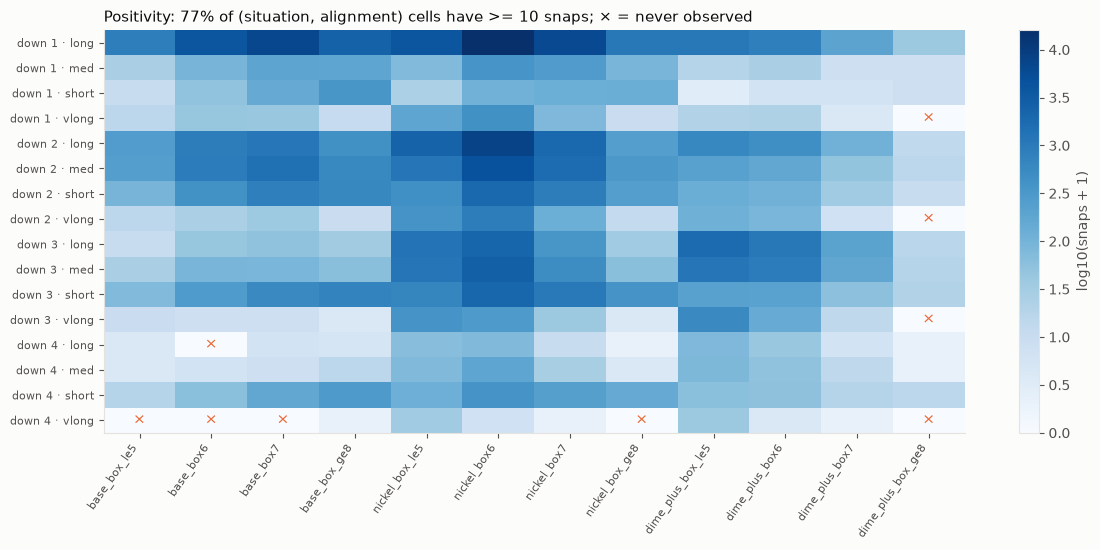

In [7]:
est = identify.identify_estimand(identify.build_causal_model(train, graph=graph))
print(f"DoWhy: backdoor-identified via {len(est.get_backdoor_variables())} adjustment variables")
pos_ = identify.check_positivity(train, cfg["positivity"]["min_count"])
cov = pos_["coverage"].set_index(pos_["strata_cols"])[list(range(ds.n_actions))]
cov.columns = order
fig, ax = plt.subplots(figsize=(12, 5.6)); ax.grid(False)
im = ax.imshow(np.log10(cov.values + 1), cmap="Blues", aspect="auto")
ax.set_xticks(range(len(order)), order, rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(len(cov)), [f"down {a} · {b}" for a, b in cov.index], fontsize=8)
for (i, j), v in np.ndenumerate(cov.values):
    if v == 0: ax.text(j, i, "×", ha="center", va="center", color=ORANGE, fontsize=11)
plt.colorbar(im, ax=ax, label="log10(snaps + 1)")
ax.set_title(f"Positivity: {pos_['pct_cells_supported']:.0%} of (situation, alignment) cells "
             f"have >= {pos_['min_count']} snaps; × = never observed", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

Pooling every defense is what makes positivity workable: most (situation, alignment) cells are
populated. The empty ones are mostly football — nobody shows dime with eight in the box on
third-and-long — and the policy is forbidden from recommending there.

## Step 3 — What coordinators actually call: π_b(A | S)

A calibrated gradient-boosted classifier over the twelve alignments. Its probabilities become
importance weights, so they are judged as probabilities: calibration is reported as a triple
(top-class confidence, every-class, and a proper scoring rule), and all diagnostics are
cross-fitted rather than in-sample.

In [8]:
beh, diag = fit_behavior_model(train, cfg)
print(f"accuracy {diag['oof_accuracy']:.3f} (majority {diag['majority_baseline']:.3f}) · "
      f"log loss {diag['oof_log_loss']:.3f} · ESS ratio {diag['ess_ratio']:.3f}")
print(f"confidence ECE {diag['confidence_ece']:.3f} · classwise ECE {diag['classwise_ece']:.3f} · "
      f"Brier {diag['brier']:.3f}")

accuracy 0.494 (majority 0.381) · log loss 1.391 · ESS ratio 0.236
confidence ECE 0.055 · classwise ECE 0.016 · Brier 0.651


## Step 4 — What would have happened: Q(S, A)

One gradient-boosted regressor over the pre-snap state *and* the alignment's two components
— package and front — rather than twelve separate models. Separate per-alignment models
estimate each cell with independent noise, inflating the spread between alignments; a policy
that maximizes Q then chases whichever cell is most overestimated. A pooled model lets a
rarely-shown alignment borrow from every alignment that shares its package or its front.

The question worth asking of any outcome model is not its fit but whether its *action effects*
behave like causes. Here are the two components' effects, by situation:

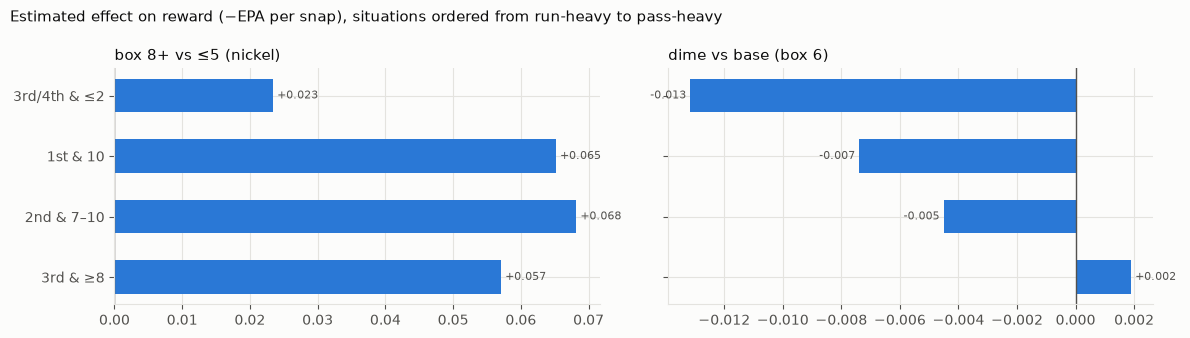

,run rate,box 8+ vs ≤5 (nickel),dime vs base (box 6)
3rd/4th & ≤2,65%,+0.0234,-0.0132
1st & 10,53%,+0.0652,-0.0074
2nd & 7–10,33%,+0.0682,-0.0045
3rd & ≥8,14%,+0.0571,+0.0019


In [9]:
q = fit_q_model(train, cfg)
dt = test.df; Qt = q.predict_all_actions(dt)
lab = {v: k for k, v in ds.action_labels.items()}
sit = {"3rd/4th & ≤2": (dt.down >= 3) & (dt.ydstogo <= 2),
       "1st & 10": (dt.down == 1) & (dt.ydstogo == 10),
       "2nd & 7–10": (dt.down == 2) & dt.ydstogo.between(7, 10),
       "3rd & ≥8": (dt.down == 3) & (dt.ydstogo >= 8)}
eff = pd.DataFrame({
    "run rate": [(dt.loc[m, "play_type"] == "run").mean() for m in sit.values()],
    "box 8+ vs ≤5 (nickel)": [(Qt[m, lab["nickel_box_ge8"]] - Qt[m, lab["nickel_box_le5"]]).mean() for m in sit.values()],
    "dime vs base (box 6)": [(Qt[m, lab["dime_plus_box6"]] - Qt[m, lab["base_box6"]]).mean() for m in sit.values()],
}, index=list(sit))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, col in zip(axes, eff.columns[1:]):
    ax.barh(eff.index, eff[col], color=BLUE, height=0.55); ax.axvline(0, color=INK2, lw=1)
    for y, v in enumerate(eff[col]):
        ax.text(v, y, f" {v:+.3f} ", va="center", ha="left" if v >= 0 else "right", fontsize=8, color=INK2)
    ax.set_title(col, loc="left", fontsize=11, color=INK)
axes[0].invert_yaxis()
fig.suptitle("Estimated effect on reward (−EPA per snap), situations ordered from run-heavy to pass-heavy",
             x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()
eff.style.format({"run rate": "{:.0%}", "box 8+ vs ≤5 (nickel)": "{:+.4f}", "dime vs base (box 6)": "{:+.4f}"})

**Read these two panels differently.** The package effect behaves like a cause: base personnel
is better where runs are likely, dime is better on third-and-long, and the sign flips in
between. The box effect does not: it is positive everywhere and *smallest* exactly where runs
are most likely — backwards from how stacking the box against the run should work.

The likeliest explanation is that on passing downs a loaded box is mostly a **pressure look**,
so its estimated effect is travelling through the pressure call — which is part of the
alignment's total effect by construction here, but is not the run-fit mechanism the box is
usually credited with — possibly mixed with the unrecorded read. Separating the run-fit channel
from the pressure channel needs the coverage-and-pressure call modeled explicitly given the
alignment. Until then, the box effect is a total effect whose mechanism is unresolved, and it
should not be read as "stack the box."

## Step 5 — Scoring the behavior policy first

Before any off-policy estimate is believed, OPE has to reproduce the coordinators' own mean
reward. The outcome model is cross-fitted so the check is not scoring its own training rows.

In [10]:
mu = crossfit_q(train, cfg)
rec = behavior_recovery_check(train, q, beh, q_all=mu, weight_clip=clip, graph_version=gv)
print(f"empirical {rec['empirical_reward']:+.4f} · DM {rec['dm_under_pi_b']:+.4f} · "
      f"DR {rec['dr_under_pi_b']:+.4f} · gap {rec['recovery_gap']:.4f} -> "
      f"{'PASS' if rec['passes'] else 'FAIL'}")

empirical +0.0077 · DM +0.0084 · DR +0.0083 · gap 0.0006 -> PASS


## Step 6 — The recommendation, on a season it never saw

The policy starts from what the coordinator already does. In each situation it keeps the
coordinator's own mix of alignments, and departs only when some well-supported alignment's
advantage over that mix clears a **one-sided 99% lower bound**. The bound comes from refitting
the outcome model on resampled games: if a call's edge moves around from resample to resample,
the data has not established it, and the recommendation is "keep doing what you do".

Resampling only measures noise. It cannot see one bias the data does show: coordinators set the
box partly from a read of what the offense is about to do. Against the state's own prediction,
heavy boxes face more runs and light boxes fewer, and within each box runs and passes are worth
very different amounts to the defense. So a box departure also has to clear an **allowance for the
read**: twice the box's estimated bias relative to the coordinator's mix (excess runs faced ×
run-minus-pass value, per box, from the training seasons). The personnel package shows no such
footprint and gets no allowance.

It is then scored on the held-out season four ways: DM trusts the outcome model, IPW and SNIPW
trust the propensities, DR needs only one of them to be right.

**Who judges.** The propensities that weight the held-out season are not the policy's. The
policy's π_b is fit on the training seasons and never sees the held-out one; the judge has to
know how coordinators actually mixed their calls *in* the season it scores, and the mix moves
from season to season — nickel with eight in the box went from 4.2% of snaps in 2023 to 1.0% in
2025. No model fit on past seasons can know that, however well calibrated. So the judge's π_b
is fit on the training seasons plus the held-out season's *other* games, with the season in the
state: each held-out game is weighted by a model that never saw it, and that uses the season's
calls but never its outcomes.

In [11]:
judge = fit_judge_behavior(train, test, cfg, beh)
pib_policy, pib = beh.propensity(dt), judge.propensity(dt)
a_te, r_te = dt["action"].to_numpy(), dt["reward"].to_numpy()
thr = cfg["policy"]["support_threshold"]
mix = pd.DataFrame({
    "share (2025)": np.bincount(a_te, minlength=ds.n_actions) / len(a_te),
    "policy's π_b": pib_policy.mean(0), "judge's π_b": pib.mean(0),
    "weight balance, policy's": weight_balance(a_te, pib_policy, thr),
    "weight balance, judge's": weight_balance(a_te, pib, thr),
}, index=list(ds.action_labels.values()))
rows = np.arange(len(a_te))
ll = lambda p: -np.log(p[rows, a_te]).mean()
print(f"held-out log loss: policy's π_b {ll(pib_policy):.4f} · judge's {ll(pib):.4f}  "
      f"(weight balance: 1 = the inverse weights average out right)")
mix.style.format("{:.3f}")


held-out log loss: policy's π_b 1.4609 · judge's 1.3607  (weight balance: 1 = the inverse weights average out right)


,share (2025),policy's π_b,judge's π_b,"weight balance, policy's","weight balance, judge's"
base_box_le5,0.010,0.019,0.015,0.906,1.308
base_box6,0.089,0.076,0.086,1.199,1.079
base_box7,0.163,0.120,0.146,1.407,1.103
base_box_ge8,0.047,0.063,0.050,0.728,0.978
nickel_box_le5,0.079,0.104,0.084,0.741,0.925
nickel_box6,0.408,0.359,0.395,1.155,0.998
nickel_box7,0.098,0.119,0.101,0.836,0.957
nickel_box_ge8,0.010,0.027,0.015,0.350,0.958
dime_plus_box_le5,0.051,0.056,0.050,1.008,1.074
dime_plus_box6,0.038,0.036,0.037,1.158,1.147


The policy's π_b, fit on the training seasons, misses the held-out season's mix in the calls that
moved: base with seven in the box is 16.3% of 2025 snaps against its 12.0%, and nickel with
eight-plus is 1.0% against its 2.7%, so the inverse weights on nickel/8+ snaps average about a
third of what they should. The judge brings both within two points and nearly every
well-supported call's weights within about 0.1 of balancing; base with five or fewer in the box,
1% of snaps, is the one it does worse on. Dime with eight-plus is almost never supported, so
neither model can weight it.

In [12]:
ensemble = fit_q_ensemble(train, cfg)
policy = learn_safe_policy(train, q, beh, cfg, ensemble)
print(f"read allowance (x{policy.allowance_scale:g}), per box:")
print(policy.read_bias_table[["component", "n", "excess_run", "run_minus_pass", "bias"]]
      .to_string(index=False, float_format=lambda v: f"{v:+.4f}"))
out = policy.act(dt)
ladder = pd.concat([
    ope_ladder(Qt, pib, pib, a_te, r_te, clip, policy_name="behavior", graph_version=gv),
    ope_ladder(Qt, pib, out["policy_probs"], a_te, r_te, clip, policy_name="safe", graph_version=gv),
], ignore_index=True)
v_b = dr_policy_value(Qt, pib, pib, a_te, r_te, clip, policy_name="behavior", graph_version=gv)
v_p = dr_policy_value(Qt, pib, out["policy_probs"], a_te, r_te, clip, policy_name="safe", graph_version=gv)
dep = ~out["deferred"]
where = pd.Series(out["chosen"][dep]).map(ds.action_labels).value_counts(normalize=True)
print(f"keeps the coordinator's mix on {1 - dep.mean():.1%} of snaps · departs on {dep.mean():.1%}")
print("departures go to: " + ", ".join(f"{k} {v:.0%}" for k, v in where.head(4).items()))
from src.ope.doubly_robust import dr_per_play
from src.stats import mean_se
base = dr_per_play(Qt, pib, pib, a_te, r_te, clip)
anchored = np.where(out["deferred"][:, None], pib, out["policy_probs"])  # defer to the season's mix
for tag, probs in (("as built", out["policy_probs"]), ("deferring to the season's mix", anchored)):
    d, se = mean_se(dr_per_play(Qt, pib, probs, a_te, r_te, clip) - base, dt["game_id"].to_numpy())
    print(f"DR lift, {tag}: {d:+.4f} ± {1.96 * se:.4f}")
ladder[["policy", "estimator", "value", "se", "support_share", "ess_ratio"]]

read allowance (x2), per box:
component     n  excess_run  run_minus_pass    bias
  box_le5 20100     -0.0501         -0.1424 +0.0071
     box6 51002     +0.0019         +0.0053 +0.0000
     box7 25488     +0.0179         +0.1047 +0.0019
  box_ge8  8631     +0.0620         +0.0939 +0.0058


keeps the coordinator's mix on 93.4% of snaps · departs on 6.6%
departures go to: nickel_box7 38%, base_box_ge8 38%, nickel_box_ge8 9%, nickel_box6 4%
DR lift, as built: -0.0078 ± 0.0114
DR lift, deferring to the season's mix: -0.0041 ± 0.0104


,policy,estimator,value,se,support_share,ess_ratio
0,behavior,DM,+0.0035,+0.0009,+1.0000,+1.0000
1,behavior,IPW,-0.0052,+0.0074,+1.0000,+1.0000
2,behavior,SNIPW,-0.0052,+0.0074,+1.0000,+1.0000
3,behavior,DR-SN,-0.0044,+0.0074,+1.0000,+1.0000
4,safe,DM,+0.0077,+0.0009,+0.9450,+0.5766
5,safe,IPW,-0.0118,+0.0091,+0.9450,+0.5766
6,safe,SNIPW,-0.0123,+0.0095,+0.9450,+0.5766
7,safe,DR-SN,-0.0121,+0.0095,+0.9450,+0.5766


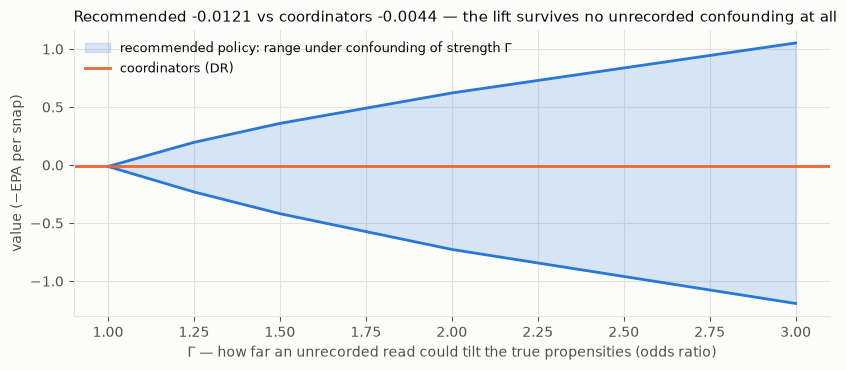

,policy,estimator,value,ci_lo,ci_hi,graph_version,robust_to_gamma
0,behavior,DR-SN,-0.0044,-0.0189,+0.0102,v3.2+8e2de51a8e2b,None
1,safe,DR-SN,-0.0121,-0.0308,+0.0066,v3.2+8e2de51a8e2b,None


In [13]:
sens = sensitivity_bounds(Qt, pib, out["policy_probs"], a_te, r_te, [1.0, 1.25, 1.5, 2.0, 3.0],
                          clip, compare_value=v_b.value, policy_name="safe")
attach_sensitivity(v_p, sens)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.fill_between(sens["gamma"], sens["v_lower"], sens["v_upper"], color=BLUE, alpha=0.18,
                label="recommended policy: range under confounding of strength Γ")
ax.plot(sens["gamma"], sens["v_lower"], color=BLUE, lw=2); ax.plot(sens["gamma"], sens["v_upper"], color=BLUE, lw=2)
ax.axhline(v_b.value, color=ORANGE, lw=2, label="coordinators (DR)")
ax.set_xlabel("Γ — how far an unrecorded read could tilt the true propensities (odds ratio)")
ax.set_ylabel("value (−EPA per snap)"); ax.legend(frameon=False, loc="upper left", fontsize=9)
g = v_p.robust_to_gamma
verdict = ("the lift survives no unrecorded confounding at all" if not g or g <= 1.0
           else f"the lift survives confounding up to Γ = {g}")
ax.set_title(f"Recommended {v_p.value:+.4f} vs coordinators {v_b.value:+.4f} — {verdict}",
             loc="left", fontsize=11)
plt.tight_layout(); plt.show()
pd.DataFrame([v_b.to_record(), v_p.to_record()])[["policy", "estimator", "value", "ci_lo", "ci_hi", "graph_version", "robust_to_gamma"]]

The recommended policy and the coordinators are **statistically indistinguishable** on the
held-out season. All four rungs of the ladder agree to within their error — no nuisance model is
misbehaving — so this is a real null, not a broken estimator.

Its deferrals need a word. Deferring, the policy plays its own estimate of the coordinator's mix,
which comes from past seasons; the judge knows the season's actual mix, so every deferral is
itself a small departure. Deferring to the season's mix instead — as the tool would in use,
sitting next to a coordinator whose calls it has — about half of the shortfall goes away.

The departures are the interesting part. The policy leaves the coordinator on about one snap in
fifteen, almost all of them toward a heavier box (seven or eight-plus). Both extremes of the box
carry read bias — an eight-man box gets the runs it was set for, a light box avoids the runs that
would hurt it — at roughly 0.006–0.007 per snap each, and the allowance makes every departure pay
twice that before it counts. What it covers is only the run/pass channel of the read, the one the
data shows; any other part of the coordinator's read is still invisible to it, which is what the
sensitivity band is for.


## Step 7 — The regression gate

The candidate is scored against the behavior-constrained greedy baseline on the same held-out
snaps with the same models, so the difference is paired and the shared noise cancels. The
gate blocks only on a proven deterioration past the margin.

In [14]:
cmp = compare_to_baseline(test, q, beh, cfg, ensemble=ensemble, candidate=policy, judge=judge)
print(cmp.report())

  V_DR(greedy_baseline) = -0.0063
  V_DR(safe_candidate ) = -0.0121
  paired difference     = -0.0058  95% CI [-0.0473, +0.0356]  (n=34449)
  non-inferiority margin= 0.0200
  verdict: NO CHANGE DETECTED  ->  gate passes


The greedy baseline — pure argmax Q over supported alignments — scores *below* the coordinators:
maximizing a noisy Q selects its most overestimated entries. Deferring to the coordinators' own
mix wherever the edge is not established is what keeps the recommendation from paying for that
noise.

## Step 8 — The coverage, given the alignment

With the alignment set, the coordinator still calls a coverage and decides whether to send
pressure. The shell is called before the offense commits, so it is part of the call on every
snap; but it is only *charted* on dropbacks — the coverage as played, and the rushers who
actually rushed — so that is where its value is estimated. The alignment joins the state: the
question is "given this alignment, which coverage".

Before modeling it, a look at the label itself.

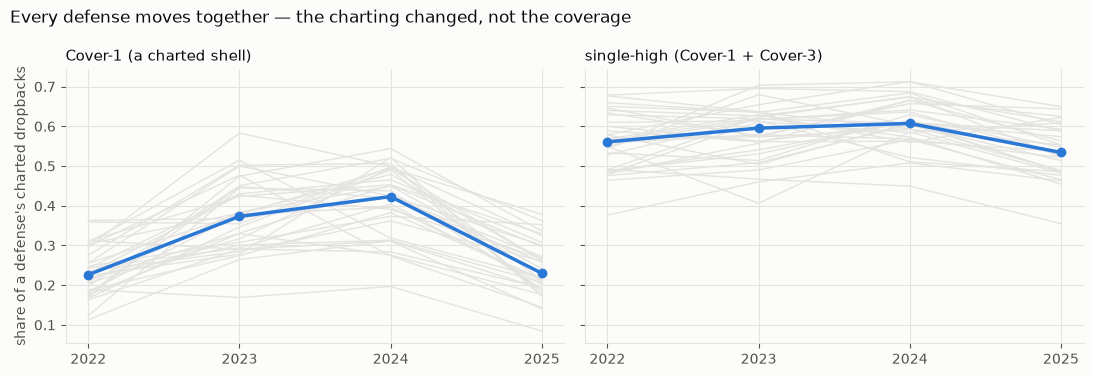

Cover-1 share: up at 30/32 defenses 2022→24, down at 32/32 in 2025


In [15]:
# What the raw charting says, season by season, for every defense.
raw = pbp[(pbp.play_type == "pass") & pbp.epa.notna() & pbp.season.isin(S)].copy()
raw["cov"] = raw.defense_coverage_type.astype("string").str.upper()
raw = raw[raw["cov"].isin(["COVER_0", "COVER_1", "COVER_2", "COVER_3", "COVER_4", "COVER_6"])]
raw["single_high"] = raw["cov"].isin(["COVER_1", "COVER_3"])
by_team = raw.groupby(["defteam", "season"]).agg(cover1=("cov", lambda c: (c == "COVER_1").mean()),
                                                 single_high=("single_high", "mean")).unstack()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, col, title in [(axes[0], "cover1", "Cover-1 (a charted shell)"),
                       (axes[1], "single_high", "single-high (Cover-1 + Cover-3)")]:
    t = by_team[col]
    for _, row in t.iterrows():
        ax.plot(t.columns, row.values, color=GRID, lw=1)
    ax.plot(t.columns, t.median().values, color=BLUE, lw=2.5, marker="o")
    ax.set_title(title, loc="left", fontsize=11); ax.set_xticks(t.columns)
axes[0].set_ylabel("share of a defense's charted dropbacks")
fig.suptitle("Every defense moves together — the charting changed, not the coverage", x=0.01,
             ha="left", fontsize=12)
plt.tight_layout(); plt.show()
d = by_team["cover1"]
print(f"Cover-1 share: up at {(d[2024] > d[2022]).sum()}/32 defenses 2022→24, "
      f"down at {(d[2025] < d[2024]).sum()}/32 in 2025")

No league changes its coverage in lockstep and then reverses in one off-season. The boundary
between Cover-1 and Cover-3 moved in the charting, and training on 2022–24 then evaluating on
2025 crosses it twice. The safety structure — one deep safety or two — barely moves. So the
coverage axis here is the structure: **Cover-0, single-high, two-high, each with or without a
blitz**, six calls. (The six-shell version is one configuration line away, for when the labels
can carry it.)

The graph is the alignment graph read for a new treatment: the alignment is now a confounder of
the coverage and is adjusted for, and selection on a charted dropback returns. The shell's
effect on whether the offense runs at all is assumed small, or already in the alignment — the
shell is never observed on runs, so it cannot be checked.

In [16]:
from src.data.features import build_level2_dataset, level2_config
cfg2 = level2_config(cfg)
ds2 = build_level2_dataset(ds, cfg2)
train2, test2 = time_aware_split(ds2, cfg["data"]["holdout_season"])
graph2 = scm.graph_for(cfg2); gv2 = graph2.version_tag()
print(graph2.describe())
beh2, diag2 = fit_behavior_model(train2, cfg2)
q2 = fit_q_model(train2, cfg2)
policy2 = learn_safe_policy(train2, q2, beh2, cfg2, fit_q_ensemble(train2, cfg2))
d2 = test2.df; out2 = policy2.act(d2)
judge2 = fit_judge_behavior(train2, test2, cfg2, beh2)
a2, r2, pib2, Q2 = d2["action"].to_numpy(), d2["reward"].to_numpy(), judge2.propensity(d2), out2["q_all"]
print(f"\n{len(ds2.df):,} charted dropbacks; π_b2 accuracy {diag2['oof_accuracy']:.3f} "
      f"(majority {diag2['majority_baseline']:.3f}), classwise ECE {diag2['classwise_ece']:.3f}")
pd.DataFrame({"policy's π_b2 (2025)": out2["pi_b"].mean(0), "judge's π_b2 (2025)": pib2.mean(0),
              "charted (2025)": np.bincount(a2, minlength=ds2.n_actions) / len(a2)},
             index=list(ds2.action_labels.values())).style.format("{:.3f}")

SCM — coverage shell x pressure given the alignment, charted dropbacks [v3.2+fde2c721376e]
  treatment=def_coverage, outcome=epa
  adjustment set (condition on): ['def_alignment', 'game_state', 'off_formation', 'off_personnel', 'off_tendencies', 'player_proxies', 'team_identity']
    -> 30 feature columns
  mediators (do NOT condition on): ['execution']
  unobserved confounders: ['coach_read', 'execution', 'offense_intent'] (bounded by the sensitivity analysis)
  SELECTED ON: ['coverage_charted'] = 1
    per charted dropback: the alignment is given, and the shell's effect on whether the offense runs is outside it
  defensive choices carried but NOT adjusted for: ['def_front']



75,705 charted dropbacks; π_b2 accuracy 0.462 (majority 0.362), classwise ECE 0.015


,policy's π_b2 (2025),judge's π_b2 (2025),charted (2025)
cover0_no_blitz,0.016,0.014,0.007
cover0_blitz,0.036,0.035,0.033
single_high_no_blitz,0.356,0.336,0.333
single_high_blitz,0.202,0.186,0.182
two_high_no_blitz,0.342,0.371,0.385
two_high_blitz,0.048,0.058,0.060


In [17]:
vb2 = dr_policy_value(Q2, pib2, pib2, a2, r2, clip, policy_name="behavior", graph_version=gv2)
vp2 = dr_policy_value(Q2, pib2, out2["policy_probs"], a2, r2, clip, policy_name="safe", graph_version=gv2)
dm2 = float(((out2["policy_probs"] - pib2) * Q2).sum(1).mean())
dep2 = ~out2["deferred"]
print(f"at the coordinator's own alignment the policy keeps his coverage mix on "
      f"{1 - dep2.mean():.1%} of dropbacks")
from src.ope.doubly_robust import dr_per_play
delta2 = dr_per_play(Q2, pib2, out2["policy_probs"], a2, r2, clip) - dr_per_play(Q2, pib2, pib2, a2, r2, clip)
print(f"lift: DR {delta2.mean():+.4f} ± {1.96 * delta2.std(ddof=1) / np.sqrt(len(delta2)):.4f} (paired) | "
      f"DM {dm2:+.4f}")

at the coordinator's own alignment the policy keeps his coverage mix on 97.8% of dropbacks
lift: DR -0.0066 ± 0.0080 (paired) | DM +0.0010


The coverage propensities are well calibrated and carry over to the new season within a few
points; the largest miss is two-high without a blitz (34.2% predicted, 38.5% charted), which the
judge's π_b closes to about a point. The recommendation keeps the coordinator's coverage on about 98% of dropbacks and is
indistinguishable from him where it departs.

The bound here is the same 99% bound as the alignment, deliberately *not* tuned on the tuning
season. Tuned that way it goes to zero: the policy departs on nearly every dropback and DR on the
tuning season reads about +0.07 per dropback — several times what the outcome model itself
claims. DR far above DM is what the coordinator's read choosing the coverage *and* improving
the result would produce — on the plays where he called a coverage the model rates lower, he
knew something — though one season's noise can produce it too. The validation aside shows how far
the read alone can carry DR in a league where the truth is known.

## Step 9 — The two levels together

The full recommendation is an alignment and a coverage for it. Scored per charted dropback —
the one sample where both are observed — against the coordinator, with each level switched on
alone and then both. The alignment's propensity here is the coordinator's *on dropbacks*: the
dropback is itself a consequence of the alignment, so the every-snap propensity would weight the
wrong population.

Then the regression gate against the previous pipeline, which recommended a coverage for one
defense on dropbacks and never chose an alignment. Both are expressed as alignment × coverage
policies on that defense's held-out dropbacks — its coverage policy with the coordinator's
alignment, against this one — and scored with the same models.

In [18]:
from src.policy.hierarchical import evaluate_factored, fit_dropback_alignment_behavior
from src.evaluation.projection_gate import projection_gate
from src.policy.hierarchical import dropback_alignment_dataset
beh1_db, _ = fit_dropback_alignment_behavior(train2, cfg)
judge1_db = fit_judge_behavior(dropback_alignment_dataset(train2, cfg),
                               dropback_alignment_dataset(test2, cfg), cfg, beh1_db)
fac = evaluate_factored(d2, cfg, policy, policy2, beh1_db, clip,
                        judges=(judge1_db, judge2))
gate = projection_gate(pbp, cfg, d2, fac, graph_version=gv2)
print(f"departures on holdout dropbacks: level 1 {fac['level1_departs']:.1%}, "
      f"level 2 {fac['level2_departs']:.1%}\n")
print(gate.report())
fac["table"].assign(**{"95% ±": 1.96 * fac["table"]["lift_se"]})[
    ["policy", "value", "lift", "95% ±"]].set_index("policy")

departures on holdout dropbacks: level 1 5.8%, level 2 2.2%

  V_DR(v2_coverage) = -0.0239
  V_DR(v3_factored) = -0.1354
  paired difference     = -0.1115  95% CI [-0.2761, +0.0531]  (n=619)
  non-inferiority margin= 0.0200
  verdict: NO CHANGE DETECTED  ->  gate passes


,value,lift,95% ±
policy,,,
coordinator,-0.0149,+0.0000,+0.0000
alignment only,-0.0238,-0.0089,+0.0194
coverage only,-0.0214,-0.0066,+0.0080
both levels,-0.0311,-0.0162,+0.0212


Read the alignment row with care. A per-dropback estimand holds the play a dropback, so the
alignment's value against the run — the reason it departs toward heavier looks — cannot appear;
only its cost against the pass can. The full-snap evaluation in Step 6 is the alignment's real
test. On this sample both levels together, and each alone, are within error of the coordinator.

The gate passes: on one defense's ~600 held-out dropbacks the difference is too uncertain to
show a regression, which is all a non-inferiority gate asks — and also all it can say. It is
the check that the new pipeline does not lose to the old one on the old one's question, not
evidence that it wins.

## Step 10 — Does it hold for other teams and other seasons?

The holdout asks whether the policy survives the next season. Two more questions, both inside
the training seasons so the holdout stays untouched.

**Invariance.** Is the effect of a call the same for every defense, every season? Environments are
team-seasons (96 of them). For each component of the call — the package, the box — against the
most common one, the test asks how far Q's out-of-fold miss on snaps that took it, minus its miss
on the reference, varies from one team-season to the next. Spread that Q already models is fine;
spread it does not model would mean a single pooled Q is wrong somewhere, and the fix would be an
invariance-penalized Q. Every snap is scored by models that never saw its game.

The null is calibrated by shuffling whole games between team-seasons. With ~17 games per
team-season, game-clustered standard errors understate the noise by 1.5–2×, so a textbook
chi-square test flags nearly everything; the shuffle measures the real noise (φ) directly.

In [19]:
from src.evaluation.invariance import (cluster_ids, environment_ids, invariance_test,
                                       pooled_effects)
from src.evaluation.transfer import crossfit_nuisances
icfg = cfg["invariance"]
dtr = train.df
nu = crossfit_nuisances(train, cfg)
a_tr, r_tr = dtr["action"].to_numpy(), dtr["reward"].to_numpy()
eff = pooled_effects(nu["q_all"], nu["pi_b"], a_tr, r_tr, dtr["game_id"].to_numpy(), cfg)
inv, inv_env, needed = invariance_test(nu["q_all"], nu["pi_b"], a_tr, r_tr,
                                       environment_ids(dtr, cfg).to_numpy(),
                                       cluster_ids(dtr), cfg, effects=eff)
print(f"{environment_ids(dtr, cfg).nunique()} team-seasons; {icfg['n_permutations']} game shuffles; "
      f"flag if p < {icfg['alpha']}/{len(inv)} and spread ≥ {icfg['min_tau']}")
print("invariance penalty needed:", needed)
inv[["contrast", "n_env", "effect", "effect_se", "modeled_sd", "unmodeled_tau", "phi", "p",
     "verdict"]].set_index("contrast")

96 team-seasons; 500 game shuffles; flag if p < 0.05/5 and spread ≥ 0.02
invariance penalty needed: False


,n_env,effect,effect_se,modeled_sd,unmodeled_tau,phi,p,verdict
contrast,,,,,,,,
base vs nickel,96,-0.0001,+0.0148,+0.0026,+0.0000,+1.1830,+0.8922,invariant
dime_plus vs nickel,69,-0.0234,+0.0204,+0.0071,+0.0489,+1.3405,+0.9002,invariant
box_le5 vs box6,96,-0.0059,+0.0145,+0.0067,+0.0159,+1.1813,+0.4451,invariant
box7 vs box6,96,+0.0269,+0.0126,+0.0029,+0.0000,+1.1423,+0.7046,invariant
box_ge8 vs box6,94,+0.0541,+0.0182,+0.0060,+0.0337,+1.2118,+0.3952,invariant


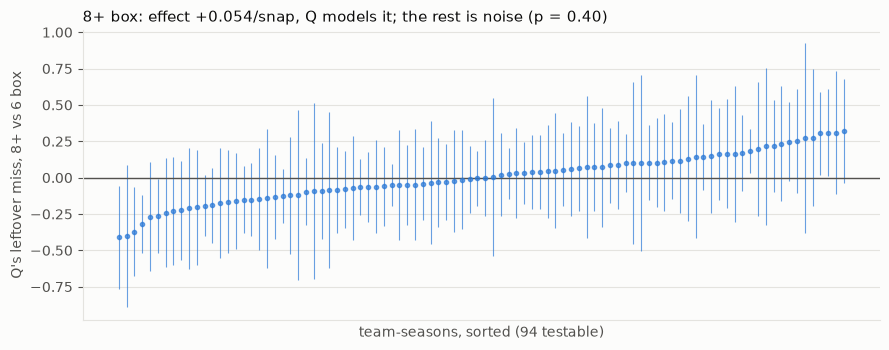

In [20]:
# The heaviest contrast, team-season by team-season: Q's leftover miss, with its
# shuffle-calibrated error. Invariance means these scatter around a common value by
# no more than their own noise.
e = inv_env[(inv_env.contrast == "box_ge8 vs box6") & inv_env.testable].sort_values("resid")
row = inv.set_index("contrast").loc["box_ge8 vs box6"]
x = np.arange(len(e))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.errorbar(x, e["resid"], yerr=1.96 * e["resid_se"], fmt="o", ms=3, color=BLUE,
            ecolor=BLUE, elinewidth=0.8, alpha=0.7)
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks([]); ax.set_xlabel(f"team-seasons, sorted ({len(e)} testable)")
ax.set_ylabel("Q's leftover miss, 8+ vs 6 box")
ax.set_title(f"8+ box: effect {row.effect:+.3f}/snap, Q models it; the rest is noise "
             f"(p = {row.p:.2f})", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

**No contrast varies beyond what the shuffled games produce**, so no invariance penalty is
needed: one pooled Q fits every defense and every season. That includes the eight-man box —
the one call with a clear effect (about +0.05 per snap against a six-man box) is the same
effect everywhere, and Q already carries it. Dime packages are untestable for about a quarter
of team-seasons, which rarely play them.

**Transfer.** Each team in turn is left out: π_b, Q, the bootstrap bound and the read allowance
are refit on the other 31 and the policy is applied to the one it never saw. The same for each
season. Every snap is scored by the game-cross-fitted models above, so a held-out team is judged
by models that know its other games — otherwise "the policy does not transfer" and "the evaluator
does not" would be the same number. The run takes about an hour
(`python run.py --config configs/v3.yaml --transfer`), so the notebook reads its output.

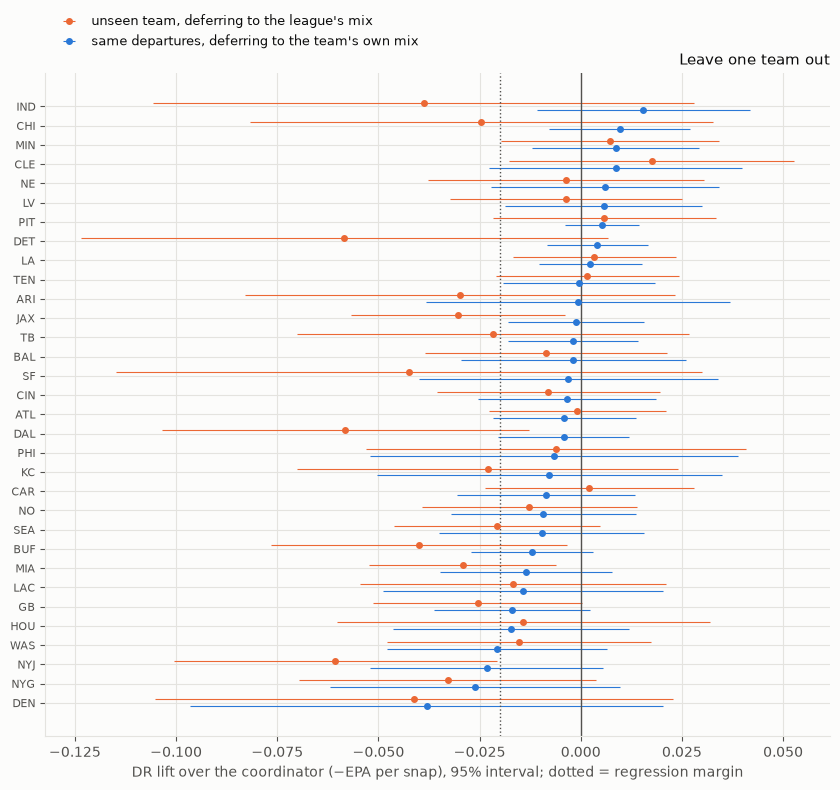

,groups,departs,lift,lift_se,lift_anchored,lift_anchored_se,gap,gap_se,n_regress
split,,,,,,,,,
leave_one_team_out,32,+0.0561,-0.0129,+0.0029,-0.0020,+0.0018,-0.0147,+0.0038,1
leave_one_season_out,3,+0.0575,+0.0014,+0.0034,+0.0024,+0.0025,+0.0036,+0.0041,0


In [21]:
path = os.path.join(cfg["output_dir"], "transfer.csv")
tr = pd.read_csv(path) if os.path.exists(path) else None
if tr is None:
    print(f"{path} not found — run `python run.py --config configs/v3.yaml --transfer` first")
else:
    from src.evaluation.transfer import summarize_transfer
    summ = summarize_transfer(tr)
    lo = tr[tr.split == "leave_one_team_out"].sort_values("lift_anchored").reset_index(drop=True)
    y = np.arange(len(lo))
    fig, ax = plt.subplots(figsize=(8.5, 8))
    ax.errorbar(lo["lift"], y + 0.18, xerr=1.96 * lo["lift_se"], fmt="o", ms=4, color=ORANGE,
                elinewidth=0.8, label="unseen team, deferring to the league's mix")
    ax.errorbar(lo["lift_anchored"], y - 0.18, xerr=1.96 * lo["lift_anchored_se"], fmt="o", ms=4,
                color=BLUE, elinewidth=0.8, label="same departures, deferring to the team's own mix")
    ax.axvline(0, color=INK2, lw=1)
    ax.axvline(-cfg["evaluation"]["regression_margin"], color=INK2, lw=1, ls=":")
    ax.set_yticks(y); ax.set_yticklabels(lo["held_out"], fontsize=8)
    ax.set_xlabel("DR lift over the coordinator (−EPA per snap), 95% interval; dotted = regression margin")
    ax.set_title("Leave one team out", loc="right", fontsize=11)
    ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.02), ncol=1, fontsize=9)
    plt.tight_layout(); plt.show()
    display(summ[["split", "groups", "departs", "lift", "lift_se", "lift_anchored",
                  "lift_anchored_se", "gap", "gap_se", "n_regress"]].set_index("split"))

**A new season is no problem**: the policy learned on two seasons does as well on the third as
the policy that saw it, and no season regresses.

**A new team is, but only in one place.** The policy defers to the coordinator's own mix on ~94%
of snaps — and for a team it never saw, its estimate of that mix is the league's. Every one of
those snaps is then a departure from what the coordinator would have called, and the coordinator's
mix carries his read of the matchup. That costs about 0.013 per snap, and it is the whole loss:
with the same departures deferring to the team's actual mix, the lift is back to zero within
error, as close to the coordinator as the in-domain policy, and no team regresses. The calls the
policy changes transfer; the calls it leaves alone need the team's own history to be left alone.
In use that history always exists — the tool sits next to a coordinator whose calls it has.

## Recommendations in the situations that matter

In [22]:
rows = []
for name, where in [("3rd/4th & short", (dt.down >= 3) & (dt.ydstogo <= 2)),
                    ("goal-to-go inside the 5", dt.yardline_100 <= 5),
                    ("1st & 10", (dt.down == 1) & (dt.ydstogo == 10)),
                    ("3rd & long", (dt.down == 3) & (dt.ydstogo >= 8))]:
    pool = dt[where]
    res = policy.act(pool)
    dep = ~res["deferred"]
    top = pd.Series(res["chosen"][dep]).map(ds.action_labels).value_counts(normalize=True)
    dc = pool["action_label"].value_counts(normalize=True)
    # the coverage, for the alignment just recommended (called on every snap)
    from src.policy.hierarchical import alignment_frames
    l2 = [policy2.act(f) for f in alignment_frames(pool, cfg)]
    pick = np.arange(len(pool))
    keep2 = np.array([l2[a]["deferred"][j] for j, a in zip(pick, res["chosen"])])
    cov = pd.Series([l2[a]["chosen"][j] for j, a in zip(pick, res["chosen"])]).map(ds2.action_labels)
    rows.append({"situation": name, "snaps": len(pool),
                 "keeps the usual mix": f"{1 - dep.mean():.0%}",
                 "departs to": f"{top.index[0]} ({top.iloc[0]:.0%} of departures)" if dep.any() else "—",
                 "coordinators' most-common": f"{dc.index[0]} ({dc.iloc[0]:.0%})",
                 "coverage: keeps the usual mix": f"{keep2.mean():.0%}",
                 "coverage, most often": cov.value_counts().index[0]})
pd.DataFrame(rows)

,situation,snaps,keeps the usual mix,departs to,coordinators' most-common,coverage: keeps the usual mix,"coverage, most often"
0,3rd/4th & short,2013,96%,base_box_ge8 (30% of departures),nickel_box6 (33%),98%,single_high_no_blitz
1,goal-to-go inside the 5,1360,95%,base_box_ge8 (40% of departures),base_box_ge8 (27%),97%,cover0_blitz
2,1st & 10,13464,93%,base_box_ge8 (53% of departures),nickel_box6 (38%),97%,single_high_no_blitz
3,3rd & long,2792,97%,nickel_box7 (39% of departures),nickel_box6 (35%),99%,two_high_no_blitz


## Validation aside — a league whose answer is known

The same pipeline, run on a simulated league built with deterrence: a heavier alignment is good
against the run, bad against the pass, *and* makes the offense less likely to run at all. A
hidden read drives both the coordinator's call and the outcome. Because the true value of any
policy is computable, three claims become checkable against truth rather than against another
estimate.

In [23]:
scfg = {**cfg, "data": {**cfg["data"]}}
syn = build_dataset(generate_synthetic_alignment(9000, seed=11, seasons=S), scfg)
s_tr, s_te = time_aware_split(syn, cfg["data"]["holdout_season"])
s_beh, _ = fit_behavior_model(s_tr, scfg); s_q = fit_q_model(s_tr, scfg)
s_out = learn_safe_policy(s_tr, s_q, s_beh, scfg, fit_q_ensemble(s_tr, scfg)).act(s_te.df)
sd = s_te.df; sa = sd["action"].to_numpy(); sr = sd["reward"].to_numpy()
sQ = s_q.predict_all_actions(sd); spib = fit_judge_behavior(s_tr, s_te, scfg, s_beh).propensity(sd)
dr_b = dr_policy_value(sQ, spib, spib, sa, sr, clip, graph_version=gv)
band = sensitivity_bounds(sQ, spib, s_out["policy_probs"], sa, sr, [1.0, 3.0], clip).set_index("gamma")
played = np.where(s_out["deferred"], sa, s_out["chosen"])  # deferring = the logged call
t_b, t_p = true_alignment_value(sd, sa), true_alignment_value(sd, played)
pd.DataFrame({
    "claim": ["recommended policy beats the coordinator in truth",
              "DR recovers the coordinator's true value",
              "the Γ=3 band contains the recommended policy's true value"],
    "evidence": [f"true {t_p:+.4f} vs {t_b:+.4f}",
                 f"DR {dr_b.value:+.4f} ± {1.96*dr_b.se:.4f} vs true {t_b:+.4f}",
                 f"[{band.loc[3.0,'v_lower']:+.4f}, {band.loc[3.0,'v_upper']:+.4f}] ∋ {t_p:+.4f}"],
    "holds": [t_p > t_b, abs(dr_b.value - t_b) <= 3 * dr_b.se,
              band.loc[3.0, "v_lower"] <= t_p <= band.loc[3.0, "v_upper"]],
})

,claim,evidence,holds
0,recommended policy beats the coordinator in truth,true +0.0265 vs +0.0179,True
1,DR recovers the coordinator's true value,DR +0.0195 ± 0.0269 vs true +0.0179,True
2,the Γ=3 band contains the recommended policy's...,"[-0.5386, +0.6131] ∋ +0.0265",True


All three are also pinned as regression tests. One caution the simulation makes concrete: on a
holdout this small, DR's error on a *new* policy's value is about as large as the true gain,
so a single point estimate there can land on either side of the truth. The real holdout is
roughly sixteen times larger, which narrows that error to about ±0.01–0.02 EPA per snap — enough
to rule out a large gain, not a small one.

### The coverage level in the simulated league

The same league with a known coverage structure on passes — the right safety structure deepens
with distance, a blitz pays more from a heavy alignment — and a coordinator whose coverage call
follows his read. Run once where the read does not touch the result, once where it does, with a
policy free to depart wherever its estimate is positive:

In [24]:
# Level 2 in a simulated league: the same coverage structure with and without the
# coordinator's read improving the result, and a policy free to depart anywhere (κ = 0).
from src.data.features import build_level2_dataset as _b2
from src.data.load import true_dropback_value
rows = []
for conf in (0.0, 0.2):
    sp = generate_synthetic_alignment(16000, seed=11, seasons=S, conf_strength=conf,
                                      coverage_effects=True)
    s2 = _b2(build_dataset(sp, cfg), cfg2)
    t2, h2 = time_aware_split(s2, cfg["data"]["holdout_season"])
    kcfg = {**cfg2, "policy": {**cfg2["policy"], "lcb_kappa": 0.0}}
    sb2, _ = fit_behavior_model(t2, cfg2); sq2 = fit_q_model(t2, cfg2)
    so = learn_safe_policy(t2, sq2, sb2, kcfg, fit_q_ensemble(t2, kcfg)).act(h2.df)
    hd = h2.df; one = np.eye(12)[hd["l1_action"].to_numpy()][:, :, None]
    joint = lambda p: (one * p[:, None, :]).reshape(len(hd), -1)
    fam = np.arange(s2.n_actions) // 2
    true = (true_dropback_value(hd, joint(so["policy_probs"]), fam)
            - true_dropback_value(hd, joint(so["pi_b"]), fam))
    ha, hr = hd["action"].to_numpy(), hd["reward"].to_numpy()
    from src.ope.doubly_robust import dr_per_play
    delta = (dr_per_play(so["q_all"], so["pi_b"], so["policy_probs"], ha, hr, clip)
             - dr_per_play(so["q_all"], so["pi_b"], so["pi_b"], ha, hr, clip))
    dr, dr_se = delta.mean(), delta.std(ddof=1) / np.sqrt(len(delta))
    dm = float(((so["policy_probs"] - so["pi_b"]) * so["q_all"]).sum(1).mean())
    rows.append({"the read improves the result": "yes" if conf else "no",
                 "true lift": true, "DR lift": dr, "DR − truth, in SEs": (dr - true) / dr_se,
                 "DM lift": dm})
pd.DataFrame(rows).set_index("the read improves the result").style.format("{:+.4f}").format("{:+.1f}", subset=["DR − truth, in SEs"])

,true lift,DR lift,"DR − truth, in SEs",DM lift
the read improves the result,,,,
no,+0.0017,+0.0583,+1.8,+0.0244
yes,-0.0099,+0.1282,+3.8,+0.0914


Free to depart wherever its estimate is positive, the policy is barely better than the
coordinator in truth in either league — and DR overstates it in both. Without the read in the
result the overstatement is noise — about 1.4 standard errors on a holdout of a couple of thousand
dropbacks; with it, DR credits the policy with what the read earned, and lands more than three
standard errors from the truth on a policy that is *worse* than the coordinator. DR running above DM shows up in both, so on its
own it is a warning, not a diagnosis. That is why the coverage bound is fixed at 99% rather than
tuned on DR, and why the remaining risk at both levels is the coordinator's read, not noise.


## Summary

- **Every snap is in.** Runs included, all defenses pooled: short yardage and goal line are
  learnable, and the alignment's deterrence effect is inside the estimand rather than
  selected away.
- **The alignment is a real, callable action** — chosen before the snap, observed on ~100% of
  plays.
- **The graph is tested, not just drawn.** Its independence claims are checked against the data
  and confirmed on a season it was not revised on; the one claim no data can check is named.
- **The recommended policy does no harm and no measurable good.** It keeps the coordinators'
  own mix unless a call's edge clears a 99% bound, matches them on the held-out season within
  error, and the gap either way is small enough for a mild unrecorded read to account for. Pure
  argmax-Q does worse.
- **The remaining risk is bias, not noise.** The calls the bound lets through are mostly heavy
  boxes, whose edge is partly the coordinator's read of a coming run.
- **The package effect looks causal; the box effect is guarded.** Box-count departures must clear
  an allowance for the coordinator's read as well as the noise bound.
- **The coverage is recommended for the alignment.** Called as safety structure × pressure — the
  fine shell labels drift with the charting — valued on charted dropbacks, and kept at the
  coordinator's mix unless its edge clears the same bound. It too is within error of the
  coordinators, and it does not regress against the previous one-defense coverage pipeline.
- **The read is the binding constraint at both levels.** Where it chooses the call and improves the
  result, DR overstates a policy's gain; the simulated league shows how much.
- **The effects are the same everywhere.** No component of the call has an effect that varies
  across the 96 team-seasons beyond noise, so one pooled Q serves every defense and no invariance
  penalty is needed.
- **The policy transfers.** Learned without a season, it does as well on that season. Learned
  without a team, its departures still hold; what it cannot know is the team's own mix to defer
  to, and that has to come from the team's history.
